In [2]:
import lightkurve as lk
import numpy as np
import astropy.io
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

C:\Users\korve\anaconda3\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [3]:
# Searching for long cadence data

search_result = lk.search_lightcurve('KIC 8639908', author='Kepler', cadence="long")

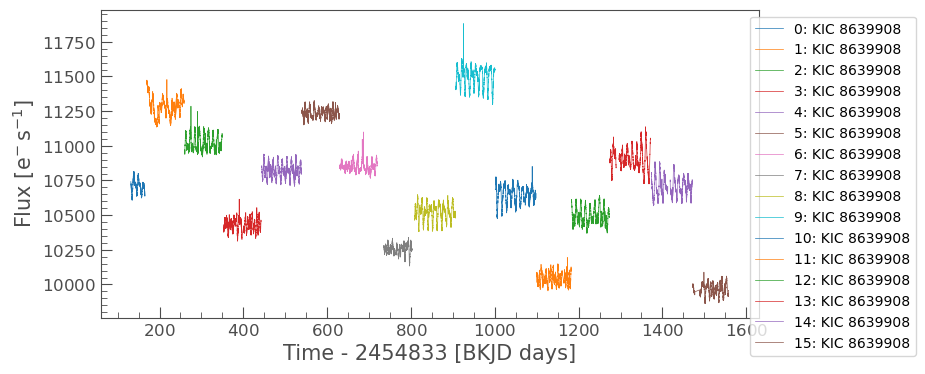

In [4]:
# Many light curves for each long cadence observation

lc_all = search_result.download_all()[0:16]
ax = lc_all.plot()

ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1.0))
plt.show()

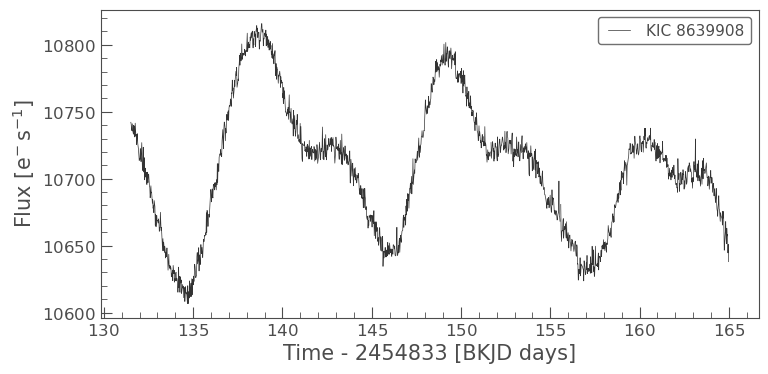

In [53]:
# Light curve for entry 0

lc = search_result[0].download()
lc.plot()
plt.show()

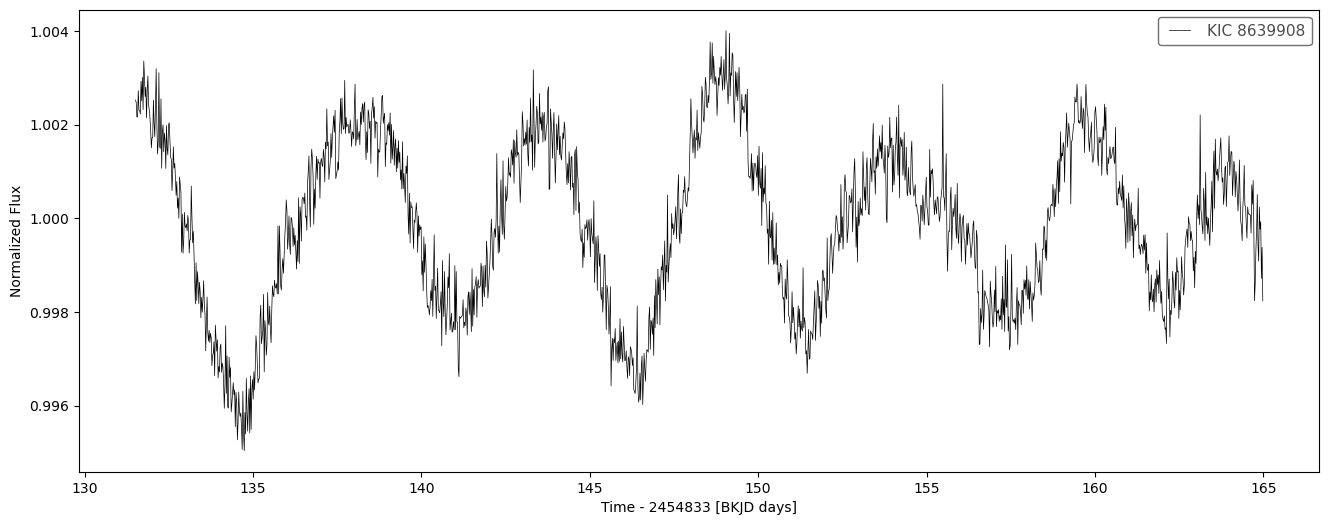

In [54]:
# Flattened light curve for entry 0

fig, ax = plt.subplots(figsize=(16,6))
lc = lc.remove_nans().flatten(window_length=401)
lc.normalize().plot(ax=ax, color='k')
plt.show()

In [55]:
# Stitching together all the light curves from before

combined_lc = lc_all.stitch()
combined_lc.plot()

<Axes: xlabel='Time - 2454833 [BKJD days]', ylabel='Normalized Flux'>

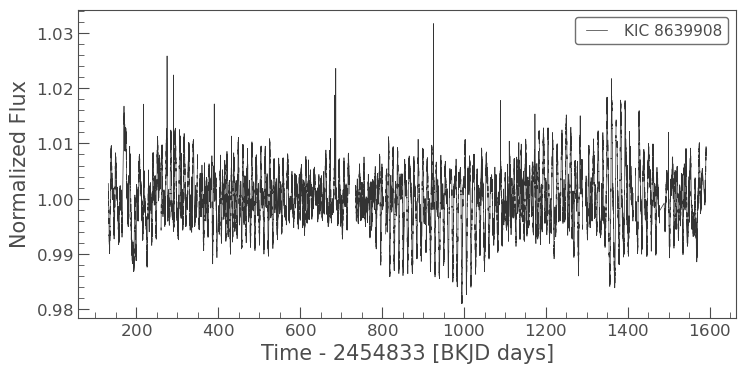

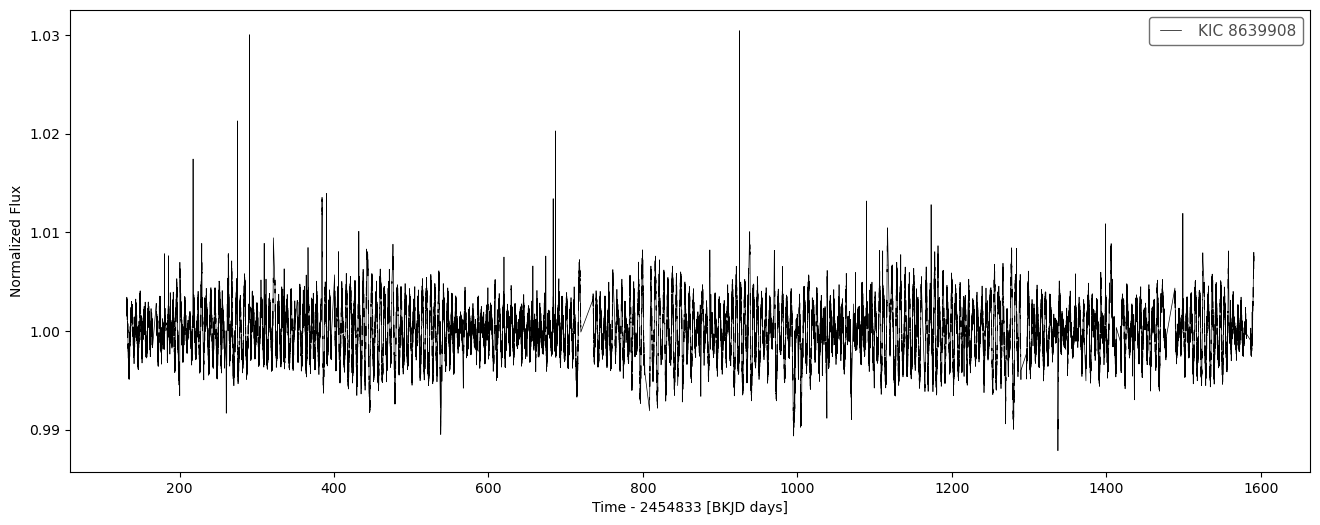

In [56]:
# The fruits of that labor

fig, ax = plt.subplots(figsize=(16,6))
lc = combined_lc.remove_nans().flatten(window_length=401)
lc.normalize().plot(ax=ax, color='k')
plt.show()

Most prominent frequency: 0.0910 1 / d
Corresponding period: 10.9901 d


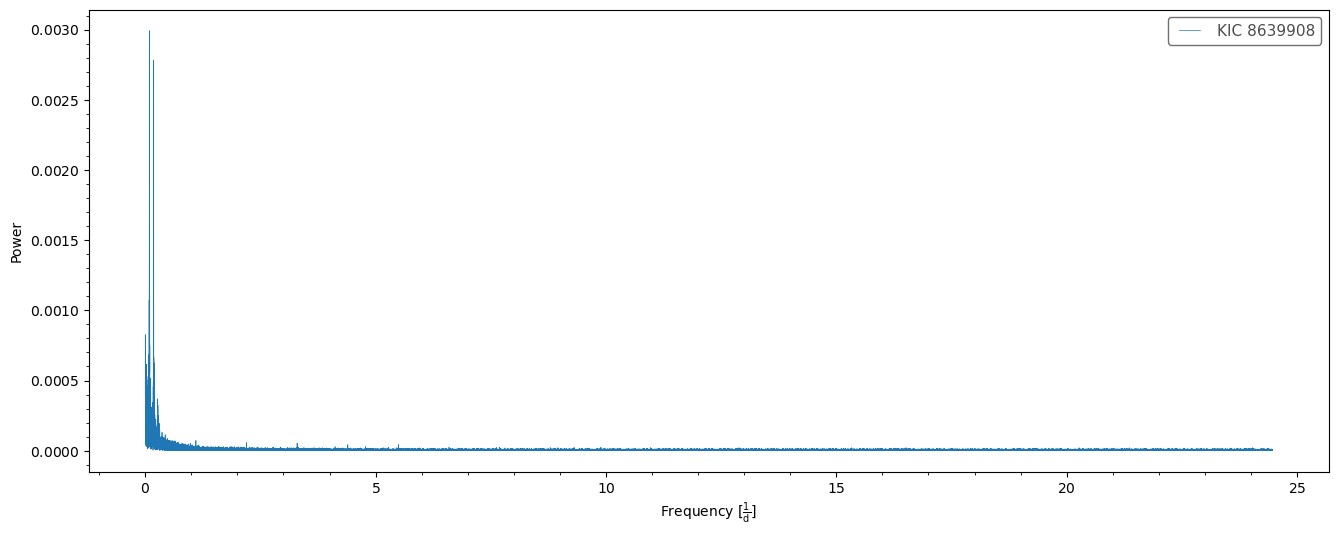

In [57]:
# Use a periodogram to determine the transit period/frequency

pg = combined_lc.to_periodogram(method="lombscargle", oversample_factor=5)
best_frequency = pg.frequency_at_max_power
best_period = pg.period_at_max_power
print(f"Most prominent frequency: {best_frequency.value:.4f} {best_frequency.unit}")
print(f"Corresponding period: {best_period.value:.4f} {best_period.unit}")

fig, ax = plt.subplots(figsize=(16,6))
combined_lc.to_periodogram().plot(ax=ax)
plt.show()

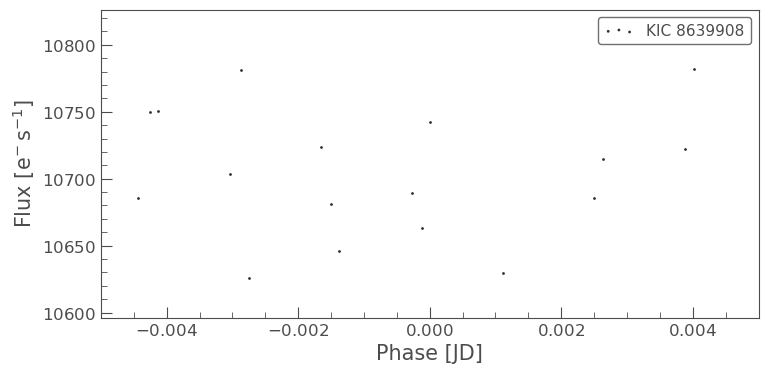

In [6]:
# Scatter plot version of the folded light curve

lc_folded = lc.fold(period = 0.910022)
lc_folded.scatter()
plt.xlim(-0.005,0.005)
plt.show()

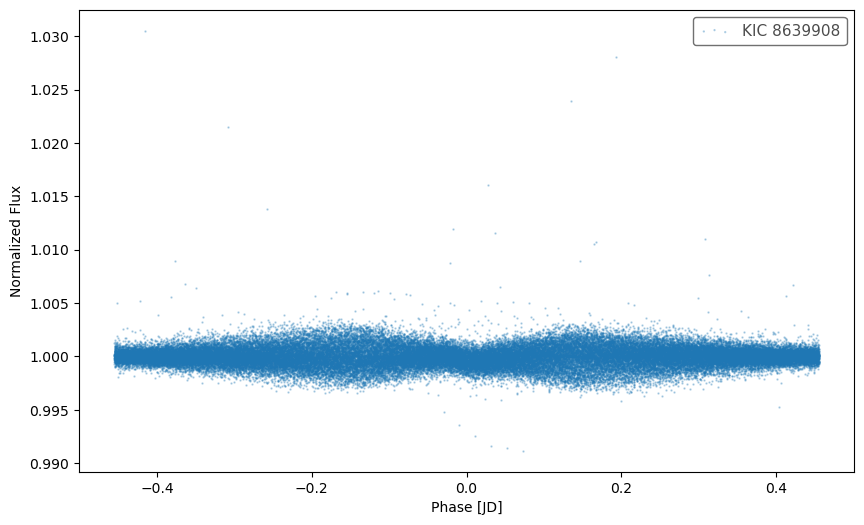

In [8]:
# Defining some important parameters

transit_time = 67.358
period = 0.910022
transit_duration = 0.25

# Initializing a fresh array

processed_lcs = []

# Looping through and normalizing, masking, and flattening existing light curve data

for lc in lc_all:
    lc = lc.remove_nans()

    #lc = lc.normalize()

    transit_mask = lc.create_transit_mask(
        period=period,
        transit_time=transit_time,
        duration=transit_duration
    )

    flat_lc = lc.flatten(
        window_length=401,
        mask=transit_mask
    )

    processed_lcs.append(flat_lc)

# Restitching the data from before

combined_lc = lk.LightCurveCollection(processed_lcs).stitch()

# Defining bin size

bin_size_days = period / 200

# Folding the new combined light curve

folded = combined_lc.fold(
    period=period,
    epoch_time=transit_time
)

# Plotting and formatting to troubleshoot

fig, ax = plt.subplots(figsize=(10, 6))

folded.scatter(ax=ax, s=2, alpha=0.3)

plt.show()

# Defining the number of bins, bin size, and other binning parameters

number_of_bins = 200

bin_size_days = orbital_period / number_of_bins

binned = folded.bin(time_bin_size=bin_size_days).normalize()

bin_size_days = 6.5 / (60 * 24)
binned = folded.bin(time_bin_size=bin_size_days)

Number of observations: 64793
Time range: 131.51190464253887 to 1591.000954362702
Flux range: 0.9911618148280383 to 1.0305183751349116
Median flux: 1.0
Flux standard deviation: 0.000983044084522588

Folded observations: 64793
Folded time range: -0.45500838473486543 to 0.45500664539443747
Binned observations: 202
Binned flux range: 0.9995614254321559 to 1.000135814217596


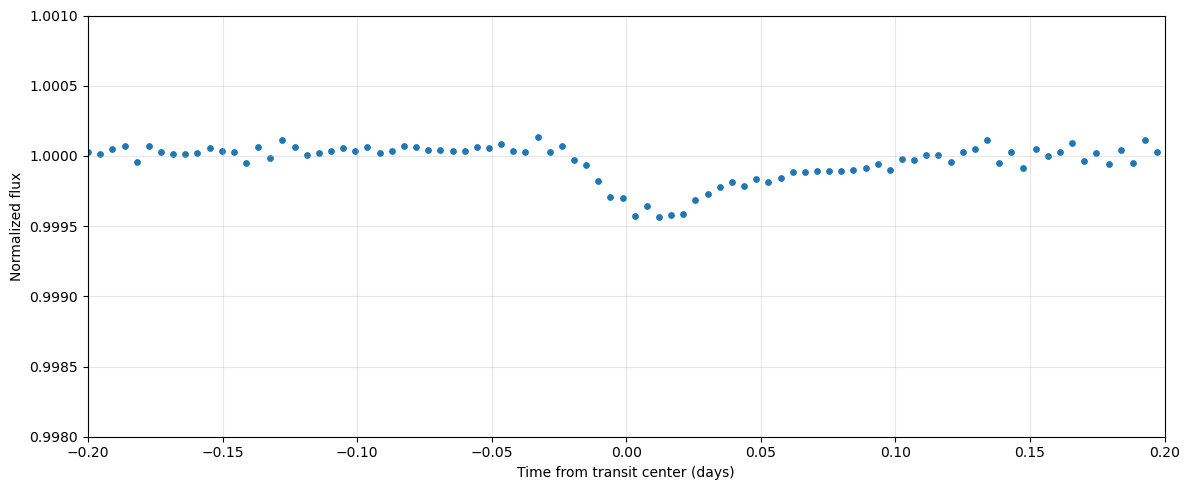

In [60]:
# Scatter plot using binned time and flux values, plus printing some data

print("Number of observations:", len(combined_lc.time))
print("Time range:", combined_lc.time.min(), "to", combined_lc.time.max())
print("Flux range:", np.nanmin(combined_lc.flux), "to", np.nanmax(combined_lc.flux))
print("Median flux:", np.nanmedian(combined_lc.flux))
print("Flux standard deviation:", np.nanstd(combined_lc.flux))

print("\nFolded observations:", len(folded.time))
print("Folded time range:", folded.time.min(), "to", folded.time.max())
print("Binned observations:", len(binned.time))
print("Binned flux range:", np.nanmin(binned.flux), "to", np.nanmax(binned.flux))

fig, ax = plt.subplots(figsize=(12, 5))

ax.scatter(
    binned.time.value,
    binned.flux.value,
    s=15
)

ax.set_xlim(-0.2, 0.2)
ax.set_ylim(0.998, 1.001)
ax.set_xlabel("Time from transit center (days)")
ax.set_ylabel("Normalized flux")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

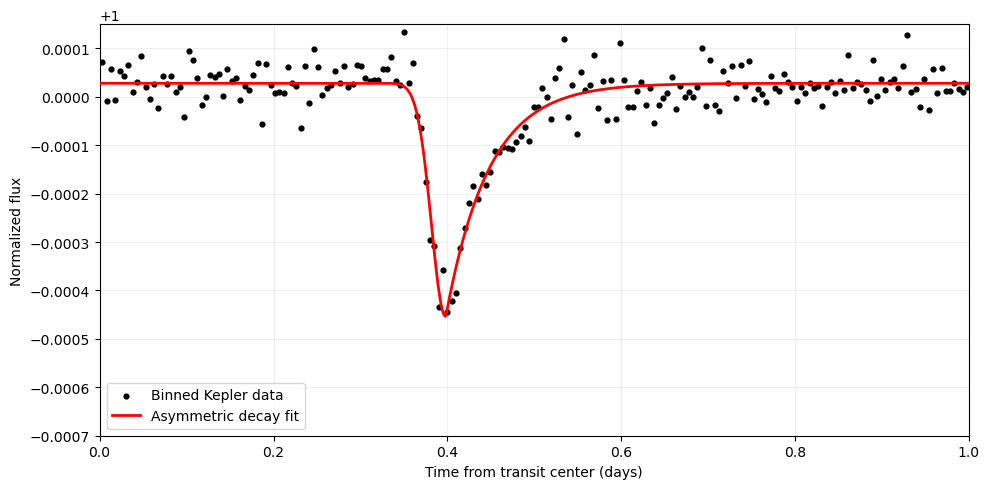

Fitted baseline: 0.0004819632848783444
Fitted transit depth: 0.016440797035282825
Fitted transit center (days): 0.04961818741237365
Fitted ingress width (days): 0.3981850389509148
Fitted exponential recovery time (days): 1.0000279593099084


In [26]:
# Importing more stuff

from scipy.optimize import curve_fit
import numpy as np
import matplotlib.pyplot as plt

# Setting x and y for the graph

x = np.asarray(binned.time.value)
y = np.asarray(binned.flux.value)

# Removing invalid values (if there are any)

valid = np.isfinite(x) & np.isfinite(y)
x = x[valid]
y = y[valid]

# switch to 0 --> 1 orbital phase
phase = (x / period + 1) % 1
phase_min = phase[np.argmin(y)]
shift = 0.40 - phase_min
phase = (phase + shift) % 1
idx = np.argsort(phase)

phase = phase[idx]
y = y[idx]

# Define a new transit model using a Gaussian shape combined with exponential decay
def transit_model(t, A, sigma, tau, t0, C):
    gaussian = A * np.exp(-0.5 * ((t - t0) / sigma)**2)
    
    recovery = A * np.exp(-(t - t0) / tau)
    
    return np.where(
        t < t0,
        C - gaussian,
        C - recovery
    )

# Initial guess for what the values in the function may be
initial_guess = [
    0.0004,       # baseline flux
    0.015,   # transit depth
    0.05,  # transit center (days)
    0.4,     # ingress width (days)
    1.0       # exponential recovery time (days)
]

# Obtaining values from scipy's curve_fit ability
popt, pcov = curve_fit(
    transit_model,
    phase,
    y,
    p0=initial_guess,
    bounds=(
        [1e-5, 0.001, 0.001, 0.35, 0.999],
        [0.001, 0.1, 0.5, 0.45, 1.001]
    ),
    maxfev=20000
)

# Defining the fitted x and y values

x_fit = np.linspace(0, 1, 1000)
y_fit = transit_model(x_fit, *popt)

# Plotting and formatting

fig, ax = plt.subplots(figsize=(10, 5))

ax.scatter(
    phase,
    y,
    color="black",
    s=12,
    label="Binned Kepler data",
    zorder=2
)

ax.plot(
    x_fit,
    y_fit,
    color="red",
    linewidth=2,
    label="Asymmetric decay fit",
    zorder=3
)

ax.set_xlim(0, 1)
ax.set_ylim(0.9993, 1.00015)

ax.set_xlabel("Time from transit center (days)")
ax.set_ylabel("Normalized flux")
ax.legend()
ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

print("Fitted baseline:", popt[0])
print("Fitted transit depth:", popt[1])
print("Fitted transit center (days):", popt[2])
print("Fitted ingress width (days):", popt[3])
print("Fitted exponential recovery time (days):", popt[4])

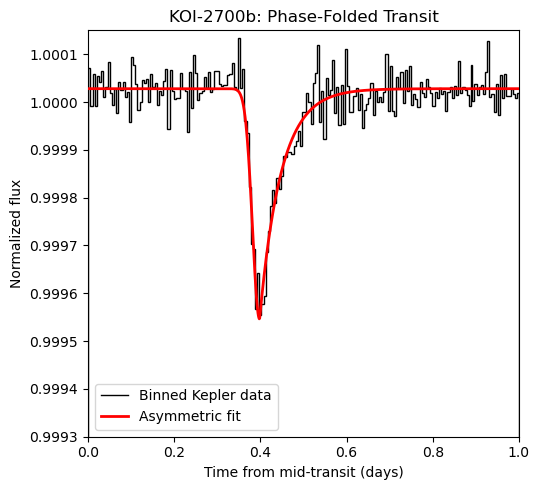

In [27]:
# Setting x and y values from binned data

x = np.asarray(binned.time.value)
y = np.asarray(binned.flux.value)

# Defining bin width

bin_width = orbital_period / 200

# Again removing invalid values

x, y = x[valid], y[valid]

# Concatenating the bins to string them together

# Width of each phase bin
phase = (x / period + 1) % 1
phase_min = phase[np.argmin(y)]
shift = 0.40 - phase_min
phase = (phase + shift) % 1
idx = np.argsort(phase)

phase = phase[idx]
y = y[idx]

phase_bin_width = 1 / 200
bin_edges = np.concatenate((
    [phase[0] - phase_bin_width / 2],
    phase + phase_bin_width / 2
))

# Plotting and formatting, much like before

fig, ax = plt.subplots(figsize=(5.5, 5))

ax.stairs(
    y,
    bin_edges,
    color="black",
    linewidth=1.0,
    label="Binned Kepler data",
    zorder=2
)

x_fit = np.linspace(0, 1, 1000)
y_fit = transit_model(x_fit, *popt)

ax.plot(
    x_fit, y_fit,
    color="red",
    linewidth=2,
    label="Asymmetric fit",
    zorder=3
)

ax.set_xlim(0, 1)
ax.ticklabel_format(
    axis='y',
    style='plain',
    useOffset=False
)
ax.set_ylim(0.9993, 1.00015)
ax.set_xlabel("Time from mid-transit (days)")
ax.set_ylabel("Normalized flux")
ax.set_title("KOI-2700b: Phase-Folded Transit")
ax.legend()
ax.grid(False)

fig.tight_layout()
plt.show()